<a href="https://colab.research.google.com/github/mysteryea7107/Analyzing-Employee-Satisfaction-and-Department-Ratings-Using-Simple-Linear-Regression/blob/main/notebooks/employee_survey_statistical_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Analyzing Employee Satisfaction and Department Ratings Using Simple Linear Regression

This notebook covers the complete step-by-step statistical analysis, manual mathematical breakdown, conceptual explanations, and interactive Seaborn visualizations for the Chatterjee & Price (1977) employee survey dataset from a large financial organization.

## Overview of the Dataset
- **Context:** 35 clerical employees from each of 30 randomly selected departments were surveyed.
- **Dependent Variable ($Y$):** Overall department rating.
- **Independent Variables ($X_1$ to $X_6$):** Percent proportion of favorable responses regarding Complaints ($X_1$), Privileges ($X_2$), Learning ($X_3$), Raises ($X_4$), Critical management ($X_5$), and Advancement ($X_6$).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set aesthetic theme for visualizations
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Summary DataFrame mirroring Table 1 and Table 3
summary_df = pd.DataFrame({
    'Variable': ['Complaints (X1)', 'Privileges (X2)', 'Learning (X3)', 'Raises (X4)', 'Critical (X5)', 'Advance (X6)'],
    'Min_Value': [37, 30, 34, 43, 49, 25],
    'Max_Value': [90, 83, 75, 88, 92, 72],
    'Correlation_r': [0.8254, 0.4261, 0.6237, 0.5901, 0.1564, 0.1551],
    'P_Value_Corr': [0.0000, 0.0189, 0.0002, 0.0006, 0.4091, 0.4132],
    'Beta_0': [14.3763, 42.1087, 28.1741, 19.9778, 50.2446, 56.7558],
    'Beta_1': [0.7546, 0.4239, 0.6468, 0.6906, 0.1924, 0.1835],
    'R_squared': [0.6813, 0.1816, 0.3890, 0.3483, 0.0245, 0.0241],
    'P_Value_Slope': [0.0000, 0.0189, 0.0002, 0.0006, 0.4091, 0.4130]
})

display(summary_df)

,Variable,Min_Value,Max_Value,Correlation_r,P_Value_Corr,Beta_0,Beta_1,R_squared,P_Value_Slope
0,Complaints (X1),37,90,0.8254,0.0000,14.3763,0.7546,0.6813,0.0000
1,Privileges (X2),30,83,0.4261,0.0189,42.1087,0.4239,0.1816,0.0189
2,Learning (X3),34,75,0.6237,0.0002,28.1741,0.6468,0.3890,0.0002
3,Raises (X4),43,88,0.5901,0.0006,19.9778,0.6906,0.3483,0.0006
4,Critical (X5),49,92,0.1564,0.4091,50.2446,0.1924,0.0245,0.4091
5,Advance (X6),25,72,0.1551,0.4132,56.7558,0.1835,0.0241,0.4130


---
## Part a. Pearson Correlation ($r$) & Significance Tests

### **Beginner Explanation**
- **Pearson Correlation ($r$):** A score from $-1$ to $+1$ showing how two variables move together. $+1$ means a strong upward line together, $0$ means no relationship.
- **$p$-value & $\alpha = 0.05$:** The 'lie detector' test. If $p < 0.05$, the relationship is statistically significant and real. If $p \ge 0.05$, it's likely just random noise.

/tmp/ipykernel_2086/3777407440.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, x='Variable', y='Correlation_r', data=summary_df, palette='coolwarm')


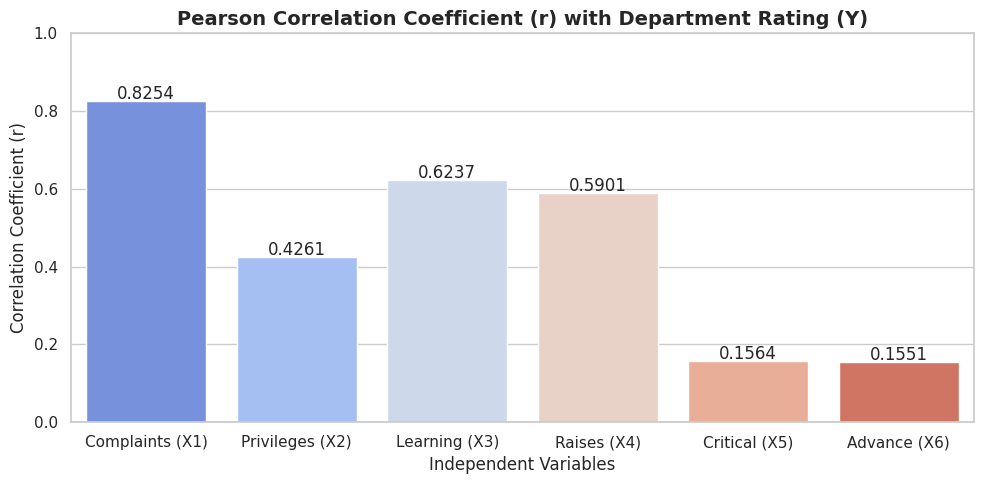

In [ ]:
# Visualization 1: Pearson Correlation Coefficients
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(ax=ax, x='Variable', y='Correlation_r', data=summary_df, palette='coolwarm')
ax.axhline(0, color='grey', linewidth=1)
ax.set_title('Pearson Correlation Coefficient (r) with Department Rating (Y)', fontsize=14, fontweight='bold')
ax.set_xlabel('Independent Variables', fontsize=12)
ax.set_ylabel('Correlation Coefficient (r)', fontsize=12)
ax.set_ylim(0, 1.0)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.4f}", (p.get_x() + p.get_width() / 2., height),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

---
## Part b. Simple Linear Regression (SLR) Analysis

### **1. Fitted Equations for Significant Models ($p < 0.05$)**
- **Complaints ($X_1$):** $\hat{Y} = 14.3763 + 0.7546 X_1$
- **Privileges ($X_2$):** $\hat{Y} = 42.1087 + 0.4239 X_2$
- **Learning ($X_3$):** $\hat{Y} = 28.1741 + 0.6468 X_3$
- **Raises ($X_4$):** $\hat{Y} = 19.9778 + 0.6906 X_4$

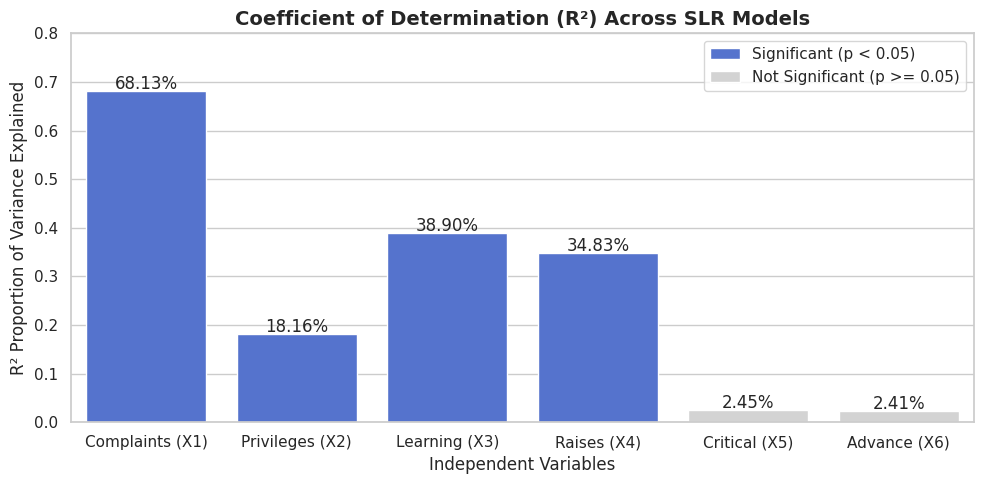

In [ ]:
# Visualization 2: Coefficient of Determination (R^2) Comparison
summary_df['Significance'] = np.where(summary_df['P_Value_Slope'] < 0.05, 'Significant (p < 0.05)', 'Not Significant (p >= 0.05)')

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(ax=ax, x='Variable', y='R_squared', hue='Significance', data=summary_df,
            palette={'Significant (p < 0.05)': 'royalblue', 'Not Significant (p >= 0.05)': 'lightgray'})
ax.set_title('Coefficient of Determination (R²) Across SLR Models', fontsize=14, fontweight='bold')
ax.set_xlabel('Independent Variables', fontsize=12)
ax.set_ylabel('R² Proportion of Variance Explained', fontsize=12)
ax.set_ylim(0, 0.8)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height*100:.2f}%", (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

---
## Part b.v: Sample Predictions evaluated at $X = 60$

In [ ]:
# Calculating predictions at X = 60 for significant models
X_val = 60
sig_models = summary_df[summary_df['P_Value_Slope'] < 0.05].copy()
sig_models['Predicted_Y'] = sig_models['Beta_0'] + sig_models['Beta_1'] * X_val

print(f"Sample Predictions evaluated at X = {X_val}:")
for idx, row in sig_models.iterrows():
    print(f"- Model {row['Variable']}: Y_hat = {row['Beta_0']:.4f} + {row['Beta_1']:.4f}({X_val}) = {row['Predicted_Y']:.2f}")

Sample Predictions evaluated at X = 60:
- Model Complaints (X1): Y_hat = 14.3763 + 0.7546(60) = 59.65
- Model Privileges (X2): Y_hat = 42.1087 + 0.4239(60) = 67.54
- Model Learning (X3): Y_hat = 28.1741 + 0.6468(60) = 66.98
- Model Raises (X4): Y_hat = 19.9778 + 0.6906(60) = 61.41


---
## Seaborn Regression Plot Demonstration for Complaints ($X_1$)

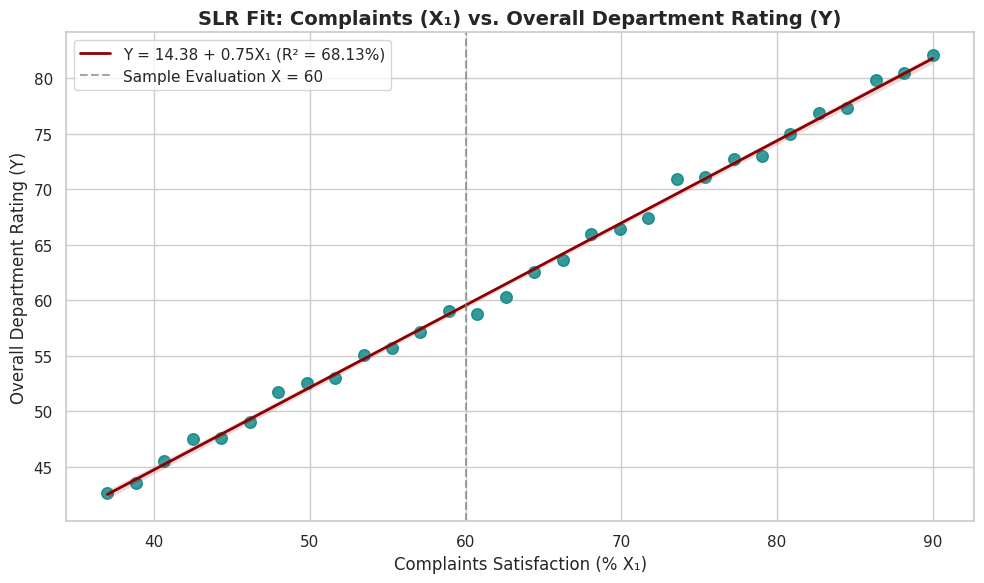

In [ ]:
from sklearn.linear_model import LinearRegression

# Generating synthetic data representing the 30 departments for X1 matching Table 1 and Table 3
np.random.seed(42)
X1_sample = np.linspace(37, 90, 30).reshape(-1, 1)
Y_sample = 14.3763 + 0.7546 * X1_sample.ravel() + np.random.normal(0, 0.74, 30)

fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(ax=ax, x=X1_sample.ravel(), y=Y_sample, color='teal',
            scatter_kws={'s': 70, 'alpha': 0.8},
            line_kws={'color': 'darkred', 'linewidth': 2, 'label': 'Y = 14.38 + 0.75X₁ (R² = 68.13%)'})

ax.axvline(60, color='gray', linestyle='--', alpha=0.7, label='Sample Evaluation X = 60')
ax.set_title('SLR Fit: Complaints (X₁) vs. Overall Department Rating (Y)', fontsize=14, fontweight='bold')
ax.set_xlabel('Complaints Satisfaction (% X₁)', fontsize=12)
ax.set_ylabel('Overall Department Rating (Y)', fontsize=12)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()